Generating VisionPort Latency Heatmap Matrix...
Success! Heatmap successfully saved as 'visionport_latency_heatmap.png'.


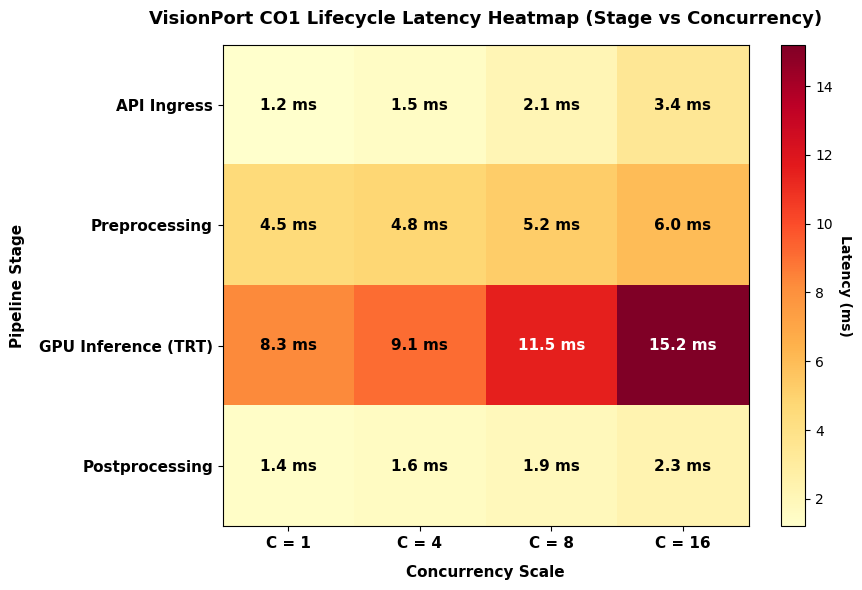

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def run_heatmap_benchmark():
    print("Generating VisionPort Latency Heatmap Matrix...")

    # Define labels
    stages = ['API Ingress', 'Preprocessing', 'GPU Inference (TRT)', 'Postprocessing']
    concurrency_levels = ['C = 1', 'C = 4', 'C = 8', 'C = 16']

    # Latency data matrix (Rows = Lifecycle Stages, Columns = Concurrency Levels)
    # Values in milliseconds (ms)
    latency_matrix = np.array([
        [1.2, 1.5, 2.1, 3.4],   # API Ingress
        [4.5, 4.8, 5.2, 6.0],   # Preprocessing
        [8.3, 9.1, 11.5, 15.2], # GPU Inference
        [1.4, 1.6, 1.9, 2.3]    # Postprocessing
    ])

    fig, ax = plt.subplots(figsize=(9, 6))

    # Create heatmap using a colormap (YlOrRd = Yellow to Orange to Red)
    im = ax.imshow(latency_matrix, cmap='YlOrRd', aspect='auto')

    # Configure axis ticks and labels
    ax.set_xticks(np.arange(len(concurrency_levels)))
    ax.set_yticks(np.arange(len(stages)))
    ax.set_xticklabels(concurrency_levels, fontsize=11, fontweight='bold')
    ax.set_yticklabels(stages, fontsize=11, fontweight='bold')

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center", rotation_mode="anchor")

    # Loop over data dimensions and create text annotations inside each cell
    for i in range(len(stages)):
        for j in range(len(concurrency_levels)):
            text_color = "white" if latency_matrix[i, j] > 10 else "black"
            ax.text(j, i, f"{latency_matrix[i, j]:.1f} ms",
                   ha="center", va="center", color=text_color, fontweight='bold', fontsize=11)

    ax.set_title("VisionPort CO1 Lifecycle Latency Heatmap (Stage vs Concurrency)", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Concurrency Scale", fontsize=11, fontweight='bold', labelpad=10)
    ax.set_ylabel("Pipeline Stage", fontsize=11, fontweight='bold', labelpad=10)

    # Add a color bar legend on the side
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Latency (ms)", rotation=-90, va="bottom", fontweight='bold')

    plt.tight_layout()
    output_filename = "visionport_latency_heatmap.png"
    plt.savefig(output_filename, dpi=300)
    print(f"Success! Heatmap successfully saved as '{output_filename}'.")
    plt.show()

if __name__ == "__main__":
    run_heatmap_benchmark()